<a href="https://colab.research.google.com/github/elmehdimoufakkir/TP4_Apprentissage_Renforcement/blob/main/Solution_TP4_Apprentissage_Renforcement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 4 — Apprentissage par renforcement (RL)



## 1. Rappels théoriques

L'apprentissage par renforcement (RL) consiste à apprendre à un **agent** à prendre des décisions en interagissant avec un **environnement**. Après chaque action, l'agent reçoit une récompense. Son objectif est de maximiser la somme des récompenses au cours du temps.

Un problème RL est souvent modélisé par un processus de décision de Markov (MDP) :

| Élément | Signification | Exemple dans CartPole |
|---|---|---|
| État `S` | Situation observée par l'agent | Position/vitesse du chariot, angle/vitesse de la tige |
| Action `A` | Décision possible | Pousser à gauche ou à droite |
| Récompense `R` | Retour reçu après l'action | Généralement +1 par pas de temps tant que la tige reste équilibrée |
| Transition `P` | Probabilité de passer à un nouvel état | Dynamique physique du chariot et de la tige |
| Facteur `γ` | Importance des récompenses futures, entre 0 et 1 | Une valeur proche de 1 valorise les récompenses futures |

### Familles d'algorithmes
- **Value-based** : apprennent la valeur des actions (Q-Learning, DQN).
- **Policy-based** : apprennent directement une politique (REINFORCE, PPO).
- **Actor-Critic** : combinent un acteur qui choisit les actions et un critique qui estime la valeur. PPO est généralement présenté comme une méthode Actor-Critic.

### CartPole-v1
L'observation contient quatre valeurs numériques. L'espace d'action est discret : `0` (gauche) ou `1` (droite). L'agent reçoit une récompense à chaque étape réussie. L'épisode se termine lorsque la tige tombe ou lorsque la limite de durée de l'environnement est atteinte.

## 2. Installation des bibliothèques

Exécuter cette cellule une seule fois dans l'environnement Python/Jupyter utilisé pour le TP.

In [1]:
%pip install -U "stable-baselines3[extra]" gymnasium matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 72.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 63.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 74.8 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [stable-baselines3]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


## 3. Importations et vérification de l'environnement

`render_mode="rgb_array"` permet de récupérer des images si nécessaire sans ouvrir obligatoirement une fenêtre graphique. Pour une fenêtre interactive locale, on pourra utiliser `render_mode="human"`.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
import stable_baselines3

from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy

print("Python :", sys.version.split()[0])
print("Gymnasium :", gym.__version__)
print("Stable-Baselines3 :", stable_baselines3.__version__)

env = gym.make("CartPole-v1")
observation, info = env.reset(seed=42)

print("\nObservation initiale :", observation)
print("Espace d'observation :", env.observation_space)
print("Espace d'action :", env.action_space)

env.close()

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Python : 3.13.18
Gymnasium : 1.4.0
Stable-Baselines3 : 2.9.2

Observation initiale : [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
Espace d'observation : Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Espace d'action : Discrete(2)


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Explication
- `gym.make("CartPole-v1")` crée l'environnement.
- `reset()` démarre un nouvel épisode et renvoie l'observation initiale ainsi qu'un dictionnaire d'informations.
- `observation_space` décrit les observations possibles.
- `action_space` décrit les actions possibles. Pour CartPole, il y en a deux.

## 4. Exemple 1 — Entraîner PPO puis tester un épisode

PPO signifie *Proximal Policy Optimization*. Dans Stable-Baselines3, `MlpPolicy` utilise un réseau de neurones adapté aux observations vectorielles.

Pour rendre l'entraînement reproductible autant que possible, on fixe une graine. On n'affiche pas la fenêtre graphique pendant l'entraînement : cela accélère l'exécution et évite les problèmes d'affichage dans certains environnements Jupyter.

In [2]:
SEED = 42
TOTAL_TIMESTEPS = 10_000

train_env = gym.make("CartPole-v1")
train_env.reset(seed=SEED)

model = PPO(
    policy="MlpPolicy",
    env=train_env,
    verbose=1,
    seed=SEED
)

print("Entraînement en cours...")
model.learn(total_timesteps=TOTAL_TIMESTEPS)
print("Entraînement terminé !")

train_env.close()

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entraînement en cours...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22       |
|    ep_rew_mean     | 22       |
| time/              |          |
|    fps             | 1280     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 24.6        |
|    ep_rew_mean          | 24.6        |
| time/                   |             |
|    fps                  | 964         |
|    iterations           | 2           |
|    time_elapsed         | 4           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.008349767 |
|    clip_fraction        | 0.0965      |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.686      |
|    explained_variance   | 0.00935     |
|    learning_rate        | 0.

### Tester l'agent sur un épisode

À chaque étape :
1. `model.predict()` choisit une action à partir de l'observation.
2. `env.step(action)` exécute l'action et renvoie la nouvelle observation, la récompense, `terminated`, `truncated` et `info`.
3. L'épisode s'arrête si `terminated` **ou** `truncated` vaut `True`.
4. On additionne les récompenses pour obtenir le score total de l'épisode.

In [3]:
test_env = gym.make("CartPole-v1")
obs, info = test_env.reset(seed=100)

done = False
total_reward = 0
steps = 0

while not done:
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = test_env.step(action)

    done = terminated or truncated
    total_reward += float(reward)
    steps += 1

test_env.close()

print("Nombre de pas :", steps)
print("Récompense totale de l'épisode :", total_reward)

Nombre de pas : 500
Récompense totale de l'épisode : 500.0


### Interprétation de l'exemple 1

Le score total correspond au nombre d'étapes pendant lesquelles l'agent a réussi à maintenir la tige en équilibre, puisque CartPole attribue normalement une récompense de `+1` à chaque étape. Un score plus élevé signifie donc que l'agent a maintenu la tige droite plus longtemps.

Un seul épisode donne toutefois une mesure limitée : son résultat peut varier selon l'état initial et l'aléatoire. Il est préférable de répéter le test sur plusieurs épisodes, comme dans l'exemple 2 du sujet.

## 5. Exemple 2 — Tester cinq épisodes et visualiser les récompenses

On conserve le modèle entraîné et on l'évalue sur cinq épisodes indépendants. On enregistre le score de chaque épisode dans `rewards_list`, puis on trace la récompense en fonction du numéro de l'épisode.

In [4]:
NUM_EPISODES = 5
rewards_list = []
lengths_list = []

eval_env = gym.make("CartPole-v1")

for ep in range(NUM_EPISODES):
    obs, info = eval_env.reset(seed=200 + ep)
    done = False
    total_reward = 0
    episode_steps = 0

    while not done:
        action, _states = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(action)

        done = terminated or truncated
        total_reward += float(reward)
        episode_steps += 1

    rewards_list.append(total_reward)
    lengths_list.append(episode_steps)
    print(f"Épisode {ep + 1} — Récompense : {total_reward}")

eval_env.close()

Épisode 1 — Récompense : 269.0
Épisode 2 — Récompense : 481.0
Épisode 3 — Récompense : 264.0
Épisode 4 — Récompense : 251.0
Épisode 5 — Récompense : 424.0


In [5]:
# Tableau récapitulatif
results = pd.DataFrame({
    "Épisode": range(1, NUM_EPISODES + 1),
    "Récompense totale": rewards_list,
    "Nombre de pas": lengths_list
})
display(results)

print("Récompense moyenne :", np.mean(rewards_list))
print("Récompense minimale :", np.min(rewards_list))
print("Récompense maximale :", np.max(rewards_list))

,Épisode,Récompense totale,Nombre de pas
0,1,269.0,269
1,2,481.0,481
2,3,264.0,264
3,4,251.0,251
4,5,424.0,424


Récompense moyenne : 337.8
Récompense minimale : 251.0
Récompense maximale : 481.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


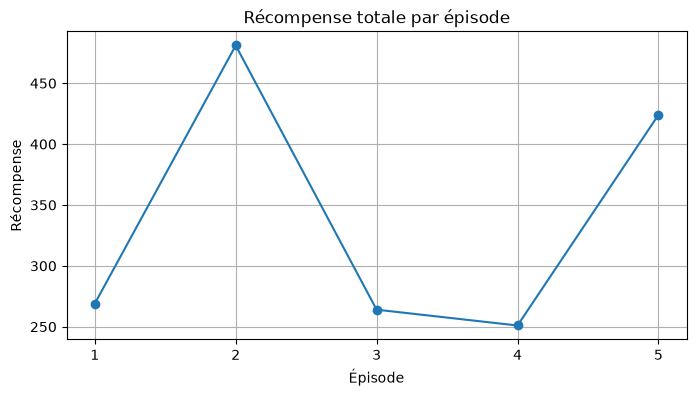

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, NUM_EPISODES + 1), rewards_list, marker="o")
plt.title("Récompense totale par épisode")
plt.xlabel("Épisode")
plt.ylabel("Récompense")
plt.xticks(range(1, NUM_EPISODES + 1))
plt.grid(True)
plt.show()

## 6. Question du TP — Expliquer les résultats des deux exemples

### Exemple 1
Le premier programme entraîne PPO pendant `10 000` pas de temps, puis teste l'agent sur un épisode. La récompense totale mesure la durée pendant laquelle l'agent maintient le système en équilibre. Si le score est élevé, l'agent a appris une politique efficace pour cet épisode. Un score faible indique que la tige est tombée rapidement ou que l'agent n'a pas encore suffisamment appris.

### Exemple 2
Le deuxième programme réutilise l'agent entraîné et le teste sur cinq épisodes. Il affiche les cinq récompenses et trace une courbe :
- une récompense élevée signifie que l'agent a maintenu la tige en équilibre longtemps ;
- des scores proches indiquent des performances relativement régulières sur ces épisodes ;
- des scores très différents indiquent que les performances varient selon les états initiaux ou les trajectoires ;
- une courbe qui monte n'est pas garantie, car il s'agit ici d'épisodes de test indépendants, et non d'une courbe de récompense pendant l'entraînement.

**Comparaison :** le premier exemple vérifie le fonctionnement de l'agent sur un épisode. Le deuxième fournit une évaluation plus informative grâce à plusieurs épisodes et à une visualisation. Pour une conclusion plus fiable, il faudrait augmenter le nombre d'épisodes de test (par exemple 20 ou 100) et calculer la moyenne et l'écart-type.

## 7. Évaluation complémentaire (facultative)

Stable-Baselines3 fournit `evaluate_policy`, qui calcule la récompense moyenne et son écart-type sur plusieurs épisodes. Cette mesure complète le graphique précédent.

In [7]:
evaluation_env = gym.make("CartPole-v1")

mean_reward, std_reward = evaluate_policy(
    model,
    evaluation_env,
    n_eval_episodes=20,
    deterministic=True
)

evaluation_env.close()

print(f"Récompense moyenne sur 20 épisodes : {mean_reward:.2f}")
print(f"Écart-type : {std_reward:.2f}")

/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


Récompense moyenne sur 20 épisodes : 404.50
Écart-type : 104.68


## 8. Sauvegarder et recharger le modèle (facultatif)

La sauvegarde permet de conserver l'agent entraîné et de le réutiliser sans refaire l'entraînement.

In [9]:
model.save("ppo_cartpole")
# Pour recharger plus tard :
# loaded_model = PPO.load("ppo_cartpole")

## 9. Conclusion générale

Dans ce TP, nous avons utilisé Gymnasium pour créer l'environnement CartPole-v1 et Stable-Baselines3 pour entraîner un agent avec PPO. L'agent observe l'état du système, choisit une action (gauche ou droite) et reçoit une récompense. L'entraînement cherche à améliorer sa politique afin de maximiser la récompense cumulée.

Le test sur un épisode permet de vérifier simplement le comportement appris. Le test sur cinq épisodes et le graphique permettent de mieux observer la stabilité des performances. Les scores obtenus doivent être interprétés à partir des sorties réellement produites lors de l'exécution du notebook.

### Difficultés possibles
- **`ModuleNotFoundError`** : exécuter la cellule d'installation puis redémarrer le kernel.
- **Pas de fenêtre graphique** : le notebook fourni n'a pas besoin d'une fenêtre pour entraîner et évaluer l'agent. Si vous voulez visualiser le jeu, créez un environnement séparé avec `render_mode="human"` dans une session Python locale avec affichage.
- **Entraînement lent** : réduire `TOTAL_TIMESTEPS` pour un essai rapide, puis l'augmenter pour une expérience plus sérieuse.
- **Résultats différents** : c'est normal ; les résultats dépendent des graines, versions et conditions d'exécution.